# Support Vector Machines: scikit-learn and from scratch (corrected version)

Changes with respect to the first version of this notebook (kept as `SVM_original.ipynb`):

1. **One split for every model.** The first version evaluated `SVC` on a random 200-example test set and the scratch SVM on a different one (the last 200 rows), so their numbers could not be compared. Now all models use the same stratified train/test split.
2. **Scaling.** SVMs are not scale invariant; `StandardScaler` is fitted on the training data only and is part of a `Pipeline`.
3. **Reproducibility.** Every random number generator has a seed (the scratch loop used an unseeded `np.random.permutation`).
4. **Fair comparison.** Besides the single split, models are compared over 10 splits (mean and standard deviation), and $C$, $\gamma$ are tuned by cross-validation on the training set only.
5. **Scratch SVM.** The training loop is the sub-gradient method of Chapter 8, with a decaying step size, and it is compared with a linear scikit-learn `SVC` on the *same* test set. The missing imports of the confusion-matrix cell were added.

Class 1 is the positive class in all metrics.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SEED = 42

## 1. Data

In [2]:
# Binary classification data with 2 features
X, y = make_classification(n_samples=1000, n_features=2, n_redundant=0, n_informative=2,
                           n_clusters_per_class=1, random_state=SEED)
print(X.shape, y.shape, "class balance:", np.bincount(y))

(1000, 2) (1000,) class balance: [501 499]


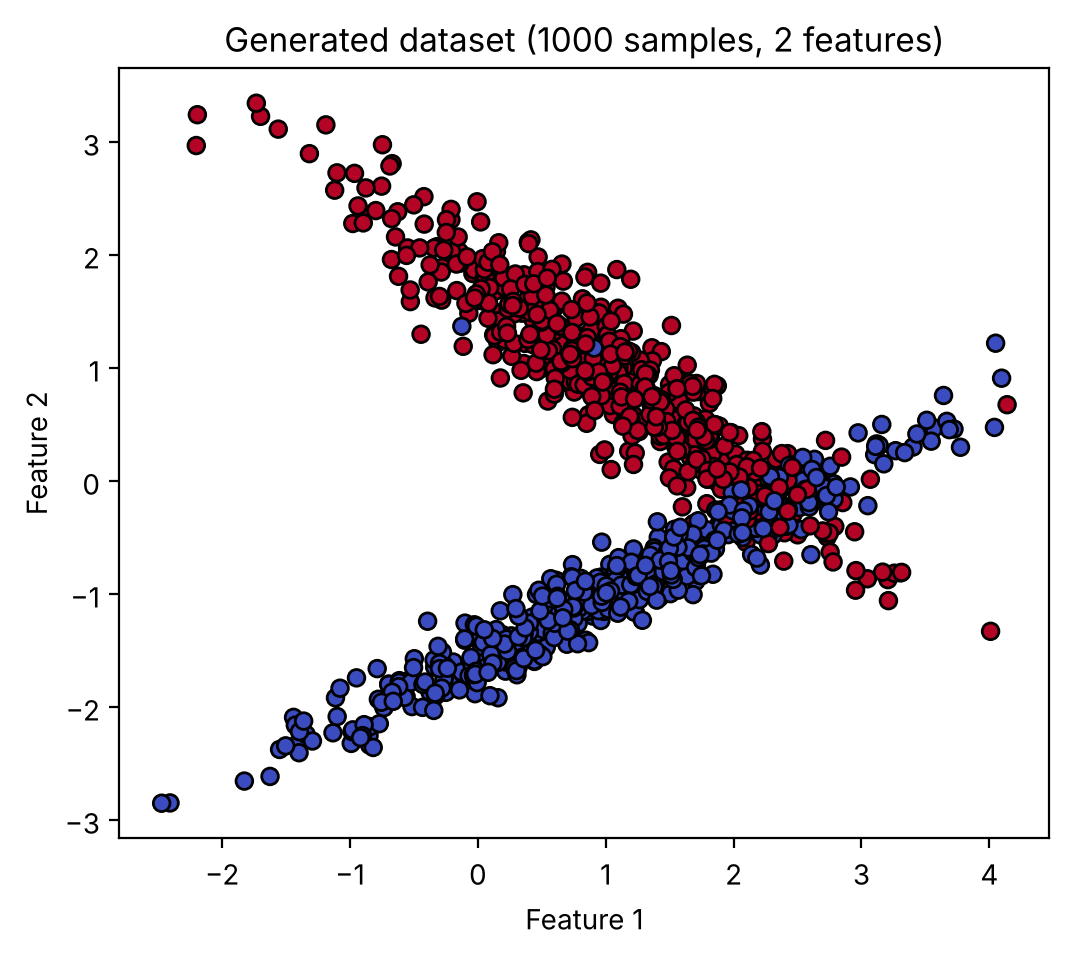

In [3]:
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors="k")
plt.title("Generated dataset (1000 samples, 2 features)")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.show()

## 2. One stratified split, used by every model below

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50, stratify=y)
print(X_train.shape, X_test.shape, np.bincount(y_train), np.bincount(y_test))

(800, 2) (200, 2) [401 399] [100 100]


## 3. scikit-learn: SVM (RBF kernel) and random forest

In [5]:
# Scaling is fitted on the training data only (inside the pipeline)
svm_model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))   # try "linear" and "poly" too
svm_model.fit(X_train, y_train)

rf_clf = RandomForestClassifier(n_estimators=50, random_state=SEED)
rf_clf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [6]:
def report(name, y_true, y_pred):
    print(f"{name:14s} accuracy {accuracy_score(y_true, y_pred):.4f}  precision {precision_score(y_true, y_pred):.4f}  "
          f"recall {recall_score(y_true, y_pred):.4f}  F1 {f1_score(y_true, y_pred):.4f}")

y_pred_svm = svm_model.predict(X_test)
y_pred_rf = rf_clf.predict(X_test)
report("SVM (RBF)", y_test, y_pred_svm)
report("Random forest", y_test, y_pred_rf)

SVM (RBF)      accuracy 0.9450  precision 0.9890  recall 0.9000  F1 0.9424
Random forest  accuracy 0.9200  precision 0.9118  recall 0.9300  F1 0.9208


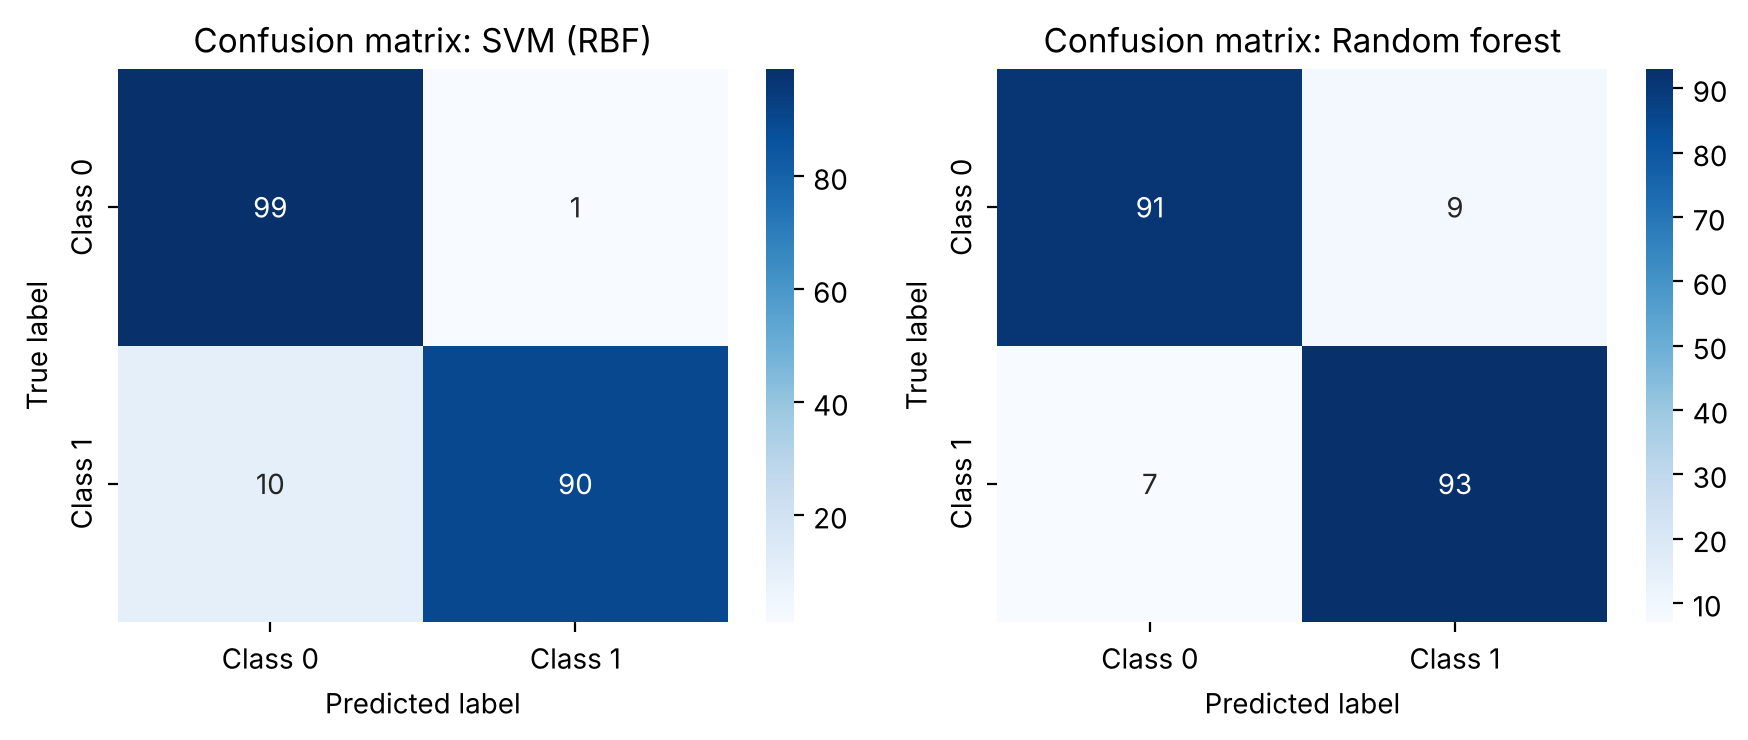

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (name, pred) in zip(axs, (("SVM (RBF)", y_pred_svm), ("Random forest", y_pred_rf))):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Class 0", "Class 1"], yticklabels=["Class 0", "Class 1"])
    ax.set_title(f"Confusion matrix: {name}"); ax.set_ylabel("True label"); ax.set_xlabel("Predicted label")
plt.tight_layout(); plt.show()

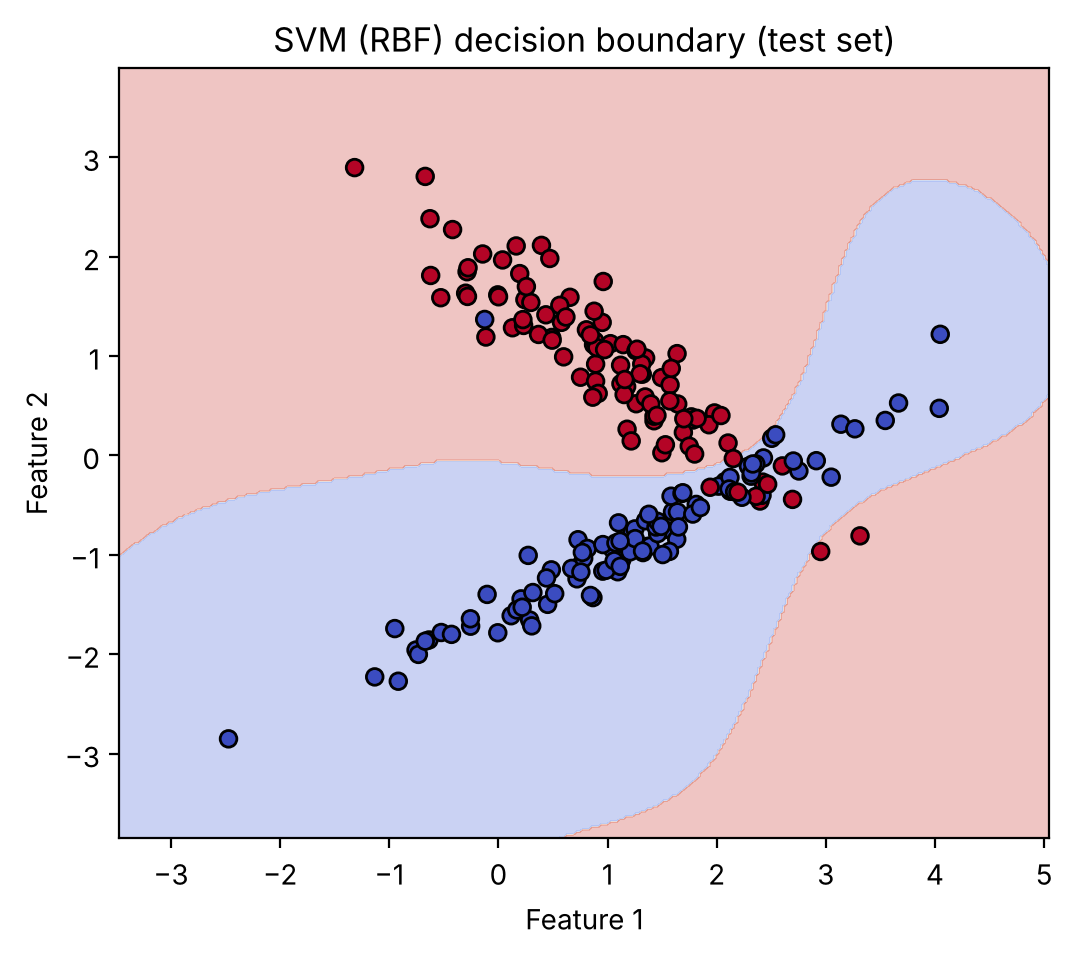

In [8]:
def plot_decision_boundary(predict, X, y, title="Decision boundary"):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
    Z = predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors="k")
    plt.title(title); plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
    plt.show()

plot_decision_boundary(svm_model.predict, X_test, y_test, "SVM (RBF) decision boundary (test set)")

## 4. A fairer comparison

On one split of 200 test examples, a difference of two examples is noise. We repeat the comparison over 10 stratified splits and report the mean and standard deviation. Hyperparameters of the SVM are tuned by 5-fold cross-validation **on the training part only**.

In [9]:
scores = []
for s in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=s, stratify=y)
    svm = make_pipeline(StandardScaler(), SVC()).fit(Xa, ya)
    rf = RandomForestClassifier(n_estimators=50, random_state=s).fit(Xa, ya)
    scores.append((svm.score(Xb, yb), rf.score(Xb, yb)))
scores = np.array(scores)
print(f"SVM (default C, gamma): {scores[:, 0].mean():.3f} +- {scores[:, 0].std():.3f}")
print(f"Random forest        : {scores[:, 1].mean():.3f} +- {scores[:, 1].std():.3f}")

SVM (default C, gamma): 0.938 +- 0.011
Random forest        : 0.940 +- 0.009


In [10]:
grid = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                    {"svc__C": 10.0 ** np.arange(-2, 4), "svc__gamma": 10.0 ** np.arange(-3, 2)}, cv=5)
grid.fit(X_train, y_train)
print("best parameters:", grid.best_params_, " CV accuracy: %.4f" % grid.best_score_)
print("test accuracy of the tuned SVM: %.4f" % grid.score(X_test, y_test))

best parameters: {'svc__C': np.float64(100.0), 'svc__gamma': np.float64(1.0)}  CV accuracy: 0.9437
test accuracy of the tuned SVM: 0.9400


## 5. SVM from scratch (linear, soft margin)

Minimise $J(\mathbf{w},b)=\tfrac12\lVert\mathbf{w}\rVert^2+C\sum_i\max(0,1-y_i(\mathbf{w}^\top\mathbf{x}_i+b))$ by stochastic sub-gradient descent. Labels are converted from $\{0,1\}$ to $\{-1,+1\}$; the **same** split and the same standardisation (statistics from the training set) are used as for scikit-learn.

In [11]:
scaler = StandardScaler().fit(X_train)
Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)
ytr, yte = 2 * y_train - 1, 2 * y_test - 1          # {0,1} -> {-1,+1}

def objective(w, b, X, y, C):
    return 0.5 * w @ w + C * np.maximum(0.0, 1.0 - y * (X @ w + b)).sum()

def train_linear_svm(X, y, C=1.0, epochs=100, lr=0.05, seed=0):
    rng = np.random.default_rng(seed)               # seeded: results are reproducible
    n = len(y)
    w, b, history = np.zeros(X.shape[1]), 0.0, []
    for epoch in range(epochs):
        eta = lr / (1.0 + 0.05 * epoch)             # decaying step size
        for i in rng.permutation(n):
            if y[i] * (X[i] @ w + b) >= 1:          # outside the margin: only the regulariser acts
                dw, db = w / n, 0.0
            else:                                    # margin violator: the hinge term is active
                dw, db = w / n - C * y[i] * X[i], -C * y[i]
            w -= eta * dw
            b -= eta * db
        history.append(objective(w, b, X, y, C))
    return w, b, history

C_PARAM = 1.0
w, b, history = train_linear_svm(Xtr, ytr, C=C_PARAM)
print("w =", np.round(w, 3), " b =", round(b, 3), " final objective =", round(history[-1], 2))

w = [-0.74   2.701]  b = 0.666  final objective = 188.12


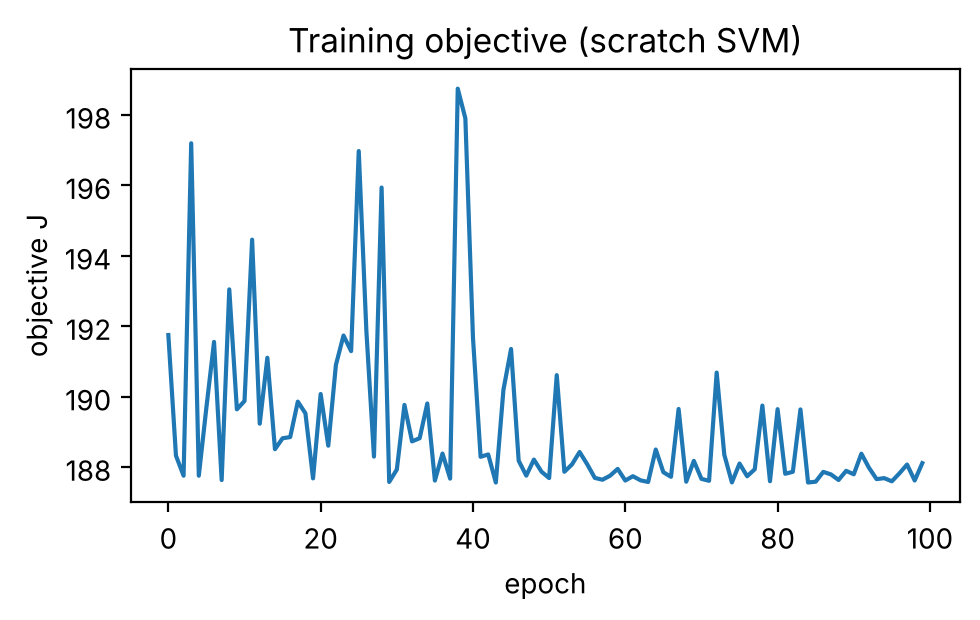

In [12]:
plt.figure(figsize=(5, 3.2))
plt.plot(history); plt.xlabel("epoch"); plt.ylabel("objective J"); plt.title("Training objective (scratch SVM)")
plt.tight_layout(); plt.show()

In [13]:
# Predictions on the same test set as the scikit-learn models
y_pred_scratch = (Xte @ w + b >= 0).astype(int)      # back to {0,1}
report("Scratch SVM", y_test, y_pred_scratch)

# Reference: scikit-learn's linear SVC with the same C on the same standardised data
ref = SVC(kernel="linear", C=C_PARAM).fit(Xtr, y_train)
report("sklearn linear", y_test, ref.predict(Xte))
w_ref, b_ref = ref.coef_[0], ref.intercept_[0]
print("objective: scratch %.2f   sklearn %.2f (lower is better)" % (objective(w, b, Xtr, ytr, C_PARAM), objective(w_ref, b_ref, Xtr, ytr, C_PARAM)))

Scratch SVM    accuracy 0.9150  precision 0.9462  recall 0.8800  F1 0.9119
sklearn linear accuracy 0.9250  precision 0.9670  recall 0.8800  F1 0.9215
objective: scratch 188.12   sklearn 187.56 (lower is better)


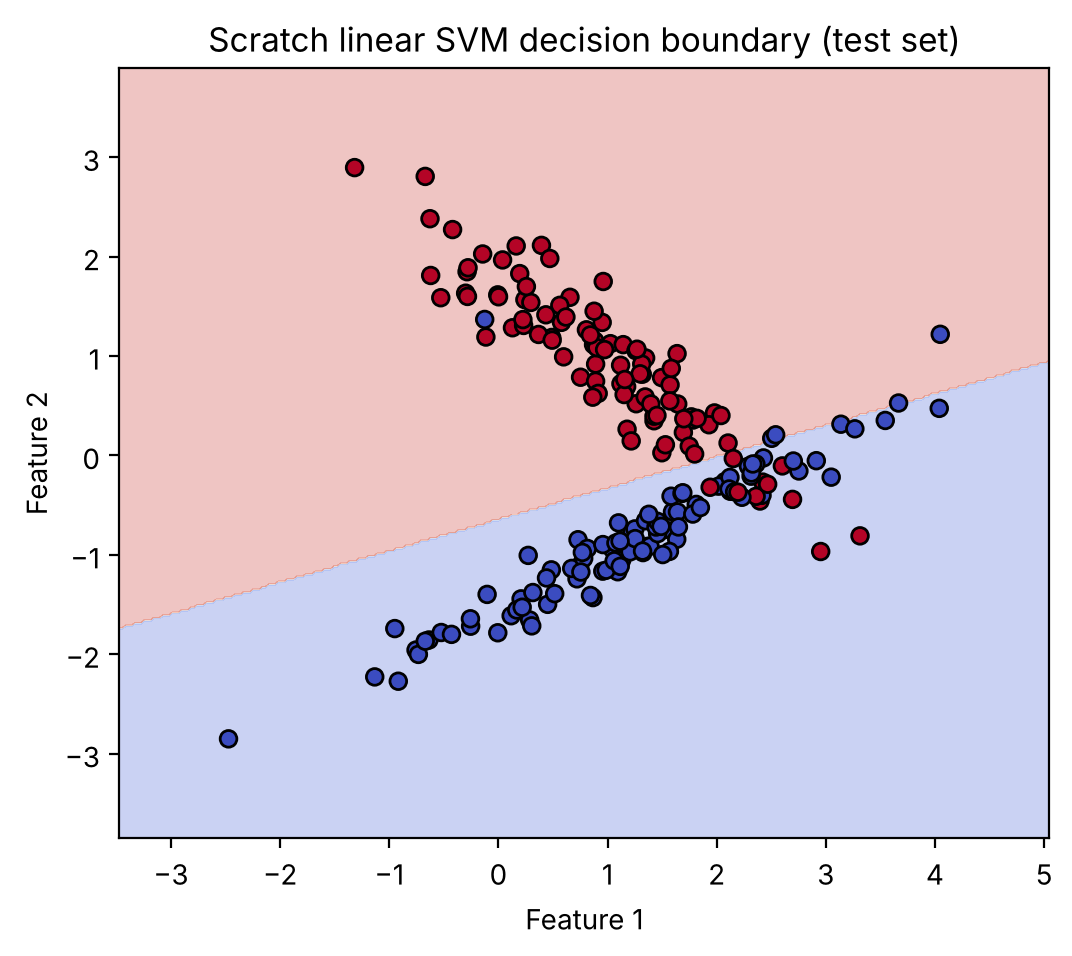

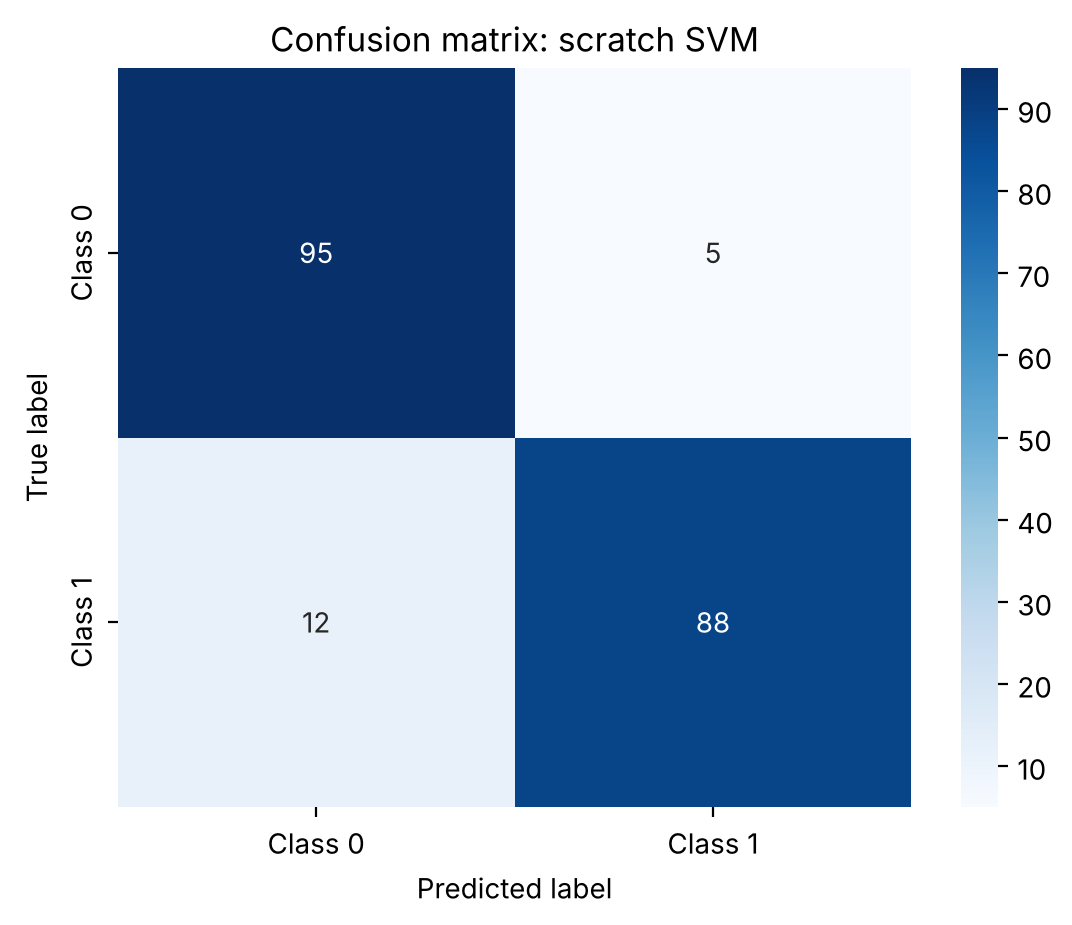

In [14]:
plot_decision_boundary(lambda P: (scaler.transform(P) @ w + b >= 0).astype(int), X_test, y_test,
                       "Scratch linear SVM decision boundary (test set)")
sns.heatmap(confusion_matrix(y_test, y_pred_scratch), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Class 0", "Class 1"], yticklabels=["Class 0", "Class 1"])
plt.title("Confusion matrix: scratch SVM"); plt.ylabel("True label"); plt.xlabel("Predicted label")
plt.show()